## Simple Linear Regression

In [1]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [4]:
df = pd.read_csv("experience_salary.csv")

In [5]:
df.head()

,experience,salary
0,0.00,26371
1,0.04,20581
2,0.08,28898
3,0.12,30014
4,0.16,17262


In [6]:
df.tail()

,experience,salary
495,19.84,158168
496,19.88,145977
497,19.92,152969
498,19.96,145781
499,20.00,148272


In [7]:
df.shape

(500, 2)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   experience  500 non-null    float64
 1   salary      500 non-null    int64  
dtypes: float64(1), int64(1)
memory usage: 7.9 KB


In [9]:
X = df[["experience"]]
y = df["salary"]

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 400
Testing records: 100


In [11]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[6534.52]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['experience']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.457e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [14]:
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Slope: 6534.5168528226095
Intercept: 24569.792369461


In [17]:
y_pred = model.predict(X_test)
print(y_test.values)
print('-----------------------')
print(y_pred)

[120773  46255 124928  73336  47893 130804 114201  61063  46576 141644
  23506  70559 130243  41502 127634 127325 158168  42453 107624 122324
 157539 154565 100107 118800  42877 141350 152969  74001  57159 112162
 147221 109515 138778  64555  28898 107192 125719  37496  77945  44051
 117834  48870 150586  80107  29935  45774  26371  31366 134006  36233
  39620  70566  52933 125144  81857  36454  68354  33642  68921  48136
 152308  94301 112527 153445  44189  38088 144064  40905  82223 127108
 114134 115207  92158  99417 104447 103922  95059  42115 144258 144078
  64878  44729 144130  67762 107769  51441  77771 131574 114130 102785
 130151 146686 123808 117602 139421 118060  45292  47646 136164  25041]
-----------------------
[119124.2512298   43715.92674823 122522.19999327  65149.14202549
  51818.72764573 127749.81347553 123306.34201561  57046.34112799
  42409.02337767 142452.47639438  26922.21843648  75408.33348442
 130886.38156488  46591.11416347 121738.05797093 126181.52943085
 1542

In [18]:
errors = y_test.values - y_pred
print(errors)

[ 1.64874877e+03  2.53907325e+03  2.40580001e+03  8.18685797e+03
 -3.92572765e+03  3.05418652e+03 -9.10534202e+03  4.01665887e+03
  4.16697662e+03 -8.08476394e+02 -3.41621844e+03 -4.84933348e+03
 -6.43381565e+02 -5.08911416e+03  5.89594203e+03  1.14347057e+03
  3.95339327e+03  1.00417874e+04  2.61879105e+02 -9.08514291e+03
  4.63129664e+03  1.39591597e+03  2.21992854e+03  9.82652141e+02
 -1.62306877e+03 -3.97766381e+03 -1.76836808e+03 -5.85080494e+03
  6.12441438e+03  9.50269712e+01 -1.76599325e+03 -3.07473438e+03
 -1.06066965e+03 -5.29899416e+03  3.80544628e+03 -4.61359235e+03
 -5.95152359e+03 -5.43578473e+03 -1.38404360e+03  2.94887999e+03
 -7.30200673e+03 -7.35402305e+01 -1.01479999e+03  7.11643775e+03
 -3.26035462e+03  1.01255056e+03  1.80120763e+03  3.92102022e+03
  7.67192368e+02  5.91283280e+03 -3.83454607e+03 -1.64042023e+03
 -5.94300585e+03 -6.78790426e+03  6.71004719e+03 -2.49172945e+03
  5.03452269e+03  4.36735550e+03 -9.10114023e+03  3.11316988e+03
 -1.64522606e+03  1.11878

In [20]:
print("Mean squared error:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

Mean squared error: 17241668.87725972
R2 Score: 0.9898349943166155


In [21]:
import matplotlib.pyplot as plt

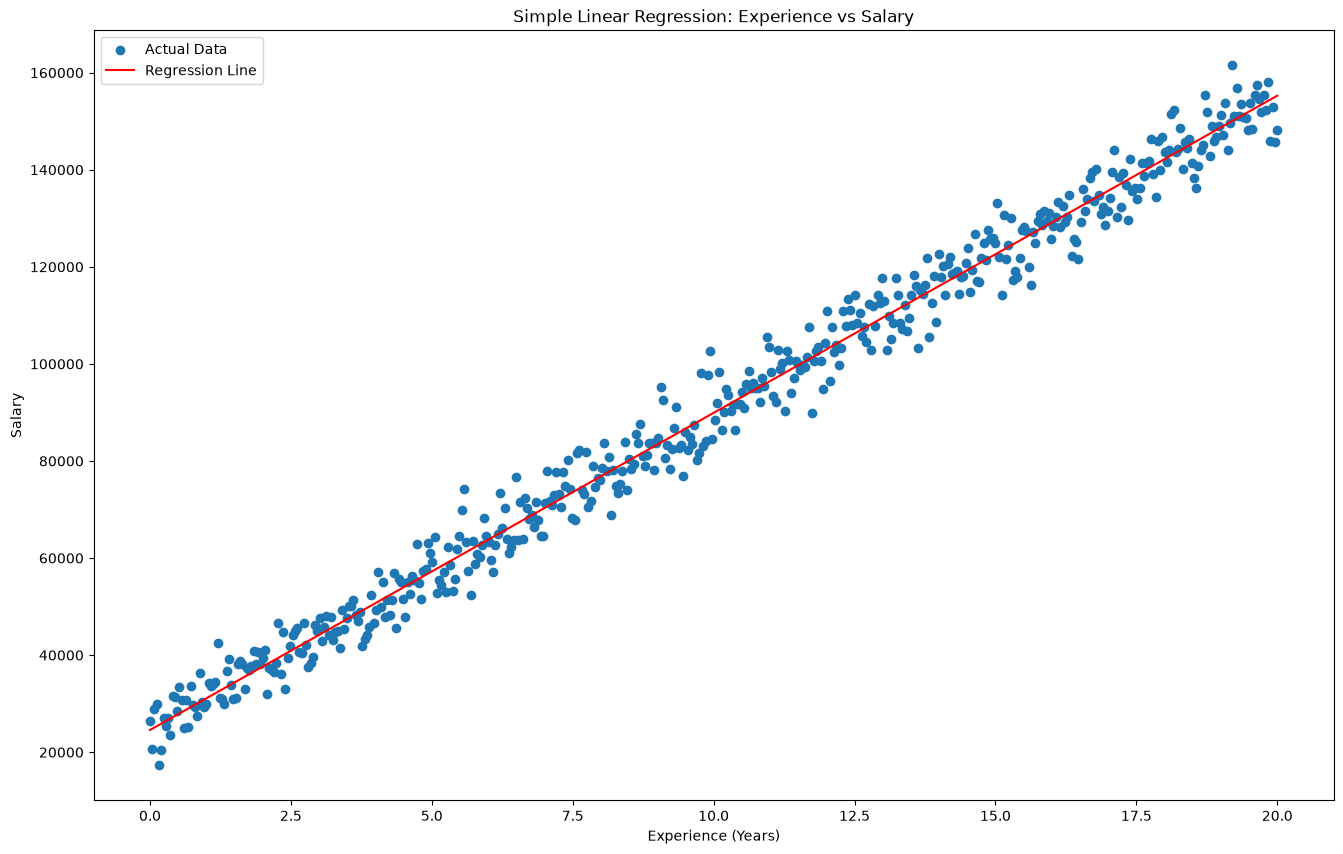

In [27]:
plt.figure(figsize = (16, 10))
plt.scatter(df["experience"], df["salary"], label = "Actual Data" )

X_line = pd.DataFrame({
    "experience" : sorted(df["experience"])
})

y_line = model.predict(X_line)

plt.plot(
    X_line["experience"],
    y_line,
    color = 'red',
    label = "Regression Line"
)

plt.xlabel("Experience (Years)")
plt.ylabel("Salary")
plt.title("Simple Linear Regression: Experience vs Salary")
plt.legend()
plt.show()

In [28]:
new_experience = pd.DataFrame({"experience": [1.0]})
predicted_salary = model.predict(new_experience)

print("Predicted Salary for 1 year Experience:",predicted_salary[0]) 

Predicted Salary for 1 year Experience: 31104.30922228361


## Multiple Linear Regression

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import LabelEncoder

In [30]:
df = pd.read_csv("Student_Performance.csv")

In [31]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [32]:
df.shape

(10000, 6)

In [33]:
df.isnull().sum()

Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64

In [34]:
df = df.dropna().copy()

In [35]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [36]:
df.shape

(10000, 6)

In [37]:
# convert categorical data into numerical data

le = LabelEncoder()

df["Extracurricular Activities"] = le.fit_transform(
    df["Extracurricular Activities"]
)

# Yes --> 1 , No --> 0
print(df.head())

   Hours Studied  Previous Scores  Extracurricular Activities  Sleep Hours  \
0              7               99                           1            9   
1              4               82                           0            4   
2              8               51                           1            7   
3              5               52                           1            5   
4              7               75                           0            8   

   Sample Question Papers Practiced  Performance Index  
0                                 1               91.0  
1                                 2               65.0  
2                                 2               45.0  
3                                 2               36.0  
4                                 5               66.0  


In [38]:
X = df.drop("Performance Index", axis = 1)
y = df["Performance Index"]

In [39]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 8000
Testing records: 2000


In [40]:
model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[2.85,1.02,0.61,0.48,0.19]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['Hours Studied','Previous Scores','Extracurricular Activities', 'Sleep Hours','Sample Question Papers Practiced']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-33.92
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


In [43]:
print("Intercept:", model.intercept_)

for feature, coefficient in zip(X.columns, model.coef_):
    print(f"{feature}: {coefficient:.4f}")

Intercept: -33.92194621555635
Hours Studied: 2.8525
Previous Scores: 1.0170
Extracurricular Activities: 0.6086
Sleep Hours: 0.4769
Sample Question Papers Practiced: 0.1918


In [47]:
equation = f"Performance Index = {model.intercept_:.4f}"

for feature, coefficient in zip(X.columns, model.coef_):
    equation += f" + ({coefficient:.4f} * {feature})"

print(equation)

Performance Index = -33.9219 + (2.8525 * Hours Studied) + (1.0170 * Previous Scores) + (0.6086 * Extracurricular Activities) + (0.4769 * Sleep Hours) + (0.1918 * Sample Question Papers Practiced)


In [50]:
y_pred = model.predict(X_test)

print(y_test.head(10).values)
print(y_pred[:10])

[51. 20. 46. 28. 41. 59. 48. 87. 37. 73.]
[54.71185392 22.61551294 47.90314471 31.28976748 43.00457042 59.07125171
 45.90347516 86.45911791 37.70014037 72.05592481]


In [52]:
errors = y_test.values - y_pred
print(errors[:10])

[-3.71185392 -2.61551294 -1.90314471 -3.28976748 -2.00457042 -0.07125171
  2.09652484  0.54088209 -0.70014037  0.94407519]


In [53]:
print("Mean squared error:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

Mean squared error: 4.082628398521855
R2 Score: 0.9889832909573145


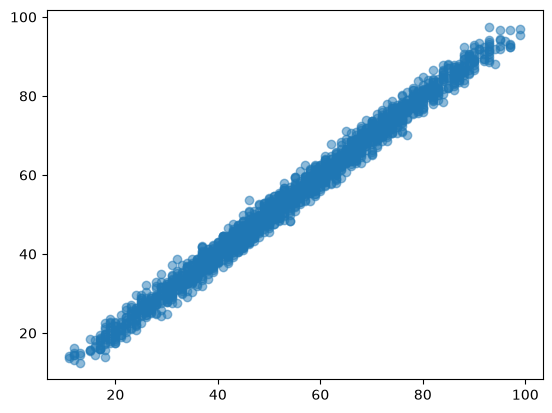

In [54]:
plt.scatter(y_test, y_pred, alpha = 0.5)

In [56]:
new_student = pd.DataFrame({
    'Hours Studied':[7],
    'Previous Scores' : [80],
    'Extracurricular Activities' : [1],
    'Sleep Hours' : [8],
    'Sample Question Papers Practiced':[5]
})

predicted_performance = model.predict(new_student)
print(predicted_performance[0])

72.78780296982552


In [57]:
# df.columns

## VIF

In [59]:
# pip install statsmodels

In [61]:
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

In [63]:
df = pd.DataFrame({
    "Hours_Studied":[2,3,4,5,6,7,8,9,10,11],
    "Practice_Papers":[1,2,4,4,6,7,7,9,10,11],
    "Sleep_Hours":[8,7,6,8,7,9,6,8,7,6],
    "Marks":[35,40,50,55,62,70,73,82,88,92]
})

df

,Hours_Studied,Practice_Papers,Sleep_Hours,Marks
0,2,1,8,35
1,3,2,7,40
2,4,4,6,50
3,5,4,8,55
4,6,6,7,62
5,7,7,9,70
6,8,7,6,73
7,9,9,8,82
8,10,10,7,88
9,11,11,6,92


In [79]:
X = df[["Hours_Studied", "Practice_Papers", "Sleep_Hours"]]

X = add_constant(X)
print(X)


vif_data = pd.DataFrame()
vif_data["Feature"] = X.columns[1:]
vif_data["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(1, X.shape[1])
]

vif_data.round(2)

   const  Hours_Studied  Practice_Papers  Sleep_Hours
0    1.0              2                1            8
1    1.0              3                2            7
2    1.0              4                4            6
3    1.0              5                4            8
4    1.0              6                6            7
5    1.0              7                7            9
6    1.0              8                7            6
7    1.0              9                9            8
8    1.0             10               10            7
9    1.0             11               11            6


,Feature,VIF
0,Hours_Studied,63.11
1,Practice_Papers,62.74
2,Sleep_Hours,1.06
